# Brezilya E-Ticaret Satış Analizi (Olist, 2017–2018)

Bu projede Brezilya'nın en büyük pazaryeri entegratörlerinden **Olist**'in ~100 bin siparişlik açık veri seti incelenmektedir.
Veri seti sipariş, ürün, müşteri, satıcı, ödeme ve müşteri yorumu bilgilerini içeren 9 ilişkili tablodan oluşur.

### İş soruları
1. **Satışlar** zaman içinde nasıl değişti? Hangi gün ve saatlerde yoğunlaşıyor?
2. Cironun büyük kısmını **hangi kategoriler** getiriyor?
3. **Bölgeler** arasında teslimat süresi ve müşteri memnuniyeti nasıl farklılaşıyor?
4. **Teslimat gecikmesi** müşteri puanını ne kadar etkiliyor?
5. Müşteriler **nasıl ödüyor**?
6. Müşteriler **geri dönüyor mu**? RFM ile müşteri segmentleri neler?
7. Ciro **satıcılar** arasında ne kadar yoğunlaşmış?

### İçindekiler
1. Kurulum ve veri yükleme
2. Veri kalitesi ve temizleme
3. Analiz tablolarının oluşturulması
4. Satış trendleri
5. Kategori analizi
6. Bölgesel analiz
7. Teslimat performansı ve müşteri memnuniyeti
8. Ödeme alışkanlıkları
9. Müşteri analizi ve RFM segmentasyonu
10. Satıcı yoğunlaşması
11. Sonuçlar ve öneriler

## 1. Kurulum ve veri yükleme

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

VERI = Path(".")
GORSEL = Path("gorseller")
GORSEL.mkdir(exist_ok=True)

# Grafik stili: sade ızgara, tek eksen, sabit renk sırası
YUZEY, ACIK_GRI, ORTA_GRI, YAZI = "#fcfcfb", "#e1e0d9", "#c3c2b7", "#52514e"
MAVI, TURUNCU = "#2a78d6", "#eb6834"
MAVI_RAMPA = LinearSegmentedColormap.from_list(
    "mavi", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.facecolor": YUZEY, "axes.facecolor": YUZEY, "savefig.facecolor": YUZEY,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": ORTA_GRI, "axes.labelcolor": YAZI, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": ACIK_GRI, "grid.linewidth": 0.6,
    "xtick.color": "#898781", "ytick.color": "#898781", "lines.linewidth": 2, "figure.dpi": 110,
})


def sayi(x, ondalik=0):
    """Sayıyı Türkçe biçimde yazar: 1234567.8 -> '1.234.568'."""
    s = f"{x:,.{ondalik}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")


YUZDE = mtick.FuncFormatter(lambda v, _: f"%{sayi(v)}")


def kaydet(fig, ad):
    fig.savefig(GORSEL / f"{ad}.png", bbox_inches="tight", dpi=150)

In [2]:
tarih = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
         "order_delivered_customer_date", "order_estimated_delivery_date"]
siparisler = pd.read_csv(VERI / "olist_orders_dataset.csv", parse_dates=tarih)
kalemler = pd.read_csv(VERI / "olist_order_items_dataset.csv", parse_dates=["shipping_limit_date"])
urunler = pd.read_csv(VERI / "olist_products_dataset.csv")
kategori_ceviri = pd.read_csv(VERI / "product_category_name_translation.csv", encoding="utf-8-sig")
musteriler = pd.read_csv(VERI / "olist_customers_dataset.csv", dtype={"customer_zip_code_prefix": str})
saticilar = pd.read_csv(VERI / "olist_sellers_dataset.csv", dtype={"seller_zip_code_prefix": str})
odemeler = pd.read_csv(VERI / "olist_order_payments_dataset.csv")
yorumlar = pd.read_csv(VERI / "olist_order_reviews_dataset.csv",
                       parse_dates=["review_creation_date", "review_answer_timestamp"])

tablolar = {"siparisler": siparisler, "kalemler": kalemler, "urunler": urunler, "musteriler": musteriler,
            "saticilar": saticilar, "odemeler": odemeler, "yorumlar": yorumlar}
pd.DataFrame({
    "satır": {ad: len(t) for ad, t in tablolar.items()},
    "sütun": {ad: t.shape[1] for ad, t in tablolar.items()},
    "eksik hücre (%)": {ad: round(t.isna().mean().mean() * 100, 2) for ad, t in tablolar.items()},
})

,satır,sütun,eksik hücre (%)
siparisler,99441,8,0.62
kalemler,112650,7,0.00
urunler,32951,9,0.83
musteriler,99441,5,0.00
saticilar,3095,4,0.00
odemeler,103886,5,0.00
yorumlar,99224,7,21.01


Tablolar `order_id`, `customer_id`, `product_id` ve `seller_id` anahtarlarıyla birbirine bağlanır.
`olist_geolocation_dataset.csv` (1 milyon satır, posta kodu → koordinat) bu analizde kullanılmadı; harita görselleştirmeleri için bir sonraki adım olarak bırakıldı.

## 2. Veri kalitesi ve temizleme

In [3]:
siparisler["order_status"].value_counts().to_frame("sipariş sayısı")

,sipariş sayısı
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2


In [4]:
aylik_ham = siparisler.groupby(siparisler["order_purchase_timestamp"].dt.to_period("M")).size()
aylik_ham[(aylik_ham < 500)].to_frame("sipariş sayısı")

,sipariş sayısı
order_purchase_timestamp,
2016-09,4
2016-10,324
2016-12,1
2018-09,16
2018-10,4


**Temizleme kararları**

- 2016 ayları ile Eylül–Ekim 2018 neredeyse boş (sistemin açılış dönemi ve veri kesimi). Trendleri bozmamak için analiz **Ocak 2017 – Ağustos 2018** aralığıyla sınırlandı.
- Satış ve teslimat analizlerinde yalnızca **teslim edilmiş** (`delivered`) siparişler kullanıldı. Bu, siparişlerin ~%97'sidir; iptal ve diğer durumlar ayrıca raporlanabilir.
- Bir siparişe birden fazla yorum yazıldıysa **en son yanıtlanan** yorum dikkate alındı.
- Çevirisi eksik iki kategori elle çevrildi. Kategorisi olmayan ürünler `unknown` olarak işaretlendi.
- Tahmini teslim tarihi gün başlangıcını (00:00) gösterdiği için, aynı gün yapılan teslimatlar **zamanında** sayıldı.

In [5]:
BASLANGIC, BITIS = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-09-01")
donem = siparisler[(siparisler["order_purchase_timestamp"] >= BASLANGIC)
                   & (siparisler["order_purchase_timestamp"] < BITIS)]
teslim = donem[(donem["order_status"] == "delivered")
               & donem["order_delivered_customer_date"].notna()].copy()
print(f"Dönemdeki sipariş: {sayi(len(donem))} | teslim edilen: {sayi(len(teslim))} "
      f"(%{sayi(len(teslim) / len(donem) * 100, 1)})")

ek_ceviri = {"pc_gamer": "pc_gamer",
             "portateis_cozinha_e_preparadores_de_alimentos": "portable_kitchen_food_processors"}
ceviri = dict(zip(kategori_ceviri["product_category_name"], kategori_ceviri["product_category_name_english"]))
ceviri.update(ek_ceviri)
urunler["kategori"] = urunler["product_category_name"].map(ceviri).fillna("unknown")

son_yorum = (yorumlar.sort_values("review_answer_timestamp")
             .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])
print(f"Yorum satırı: {sayi(len(yorumlar))} | tekilleştirilmiş: {sayi(len(son_yorum))}")

Dönemdeki sipariş: 99.092 | teslim edilen: 96.203 (%97,1)
Yorum satırı: 99.224 | tekilleştirilmiş: 98.673


## 3. Analiz tablolarının oluşturulması

İki ana tablo oluşturuldu:
- **`df`** – sipariş düzeyi: her satır bir teslim edilmiş sipariş (müşteri, tutar, teslimat süreleri, puan).
- **`kalem_df`** – ürün kalemi düzeyi: kategori ve satıcı analizleri için.

In [6]:
kalem_ozet = kalemler.groupby("order_id").agg(
    urun_adedi=("order_item_id", "count"), urun_tutari=("price", "sum"), kargo_ucreti=("freight_value", "sum"))

df = (teslim.merge(musteriler, on="customer_id")
      .merge(kalem_ozet, on="order_id")
      .merge(son_yorum, on="order_id", how="left"))

teslim_gunu = df["order_delivered_customer_date"].dt.normalize()
df["ay"] = df["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
df["siparis_tutari"] = df["urun_tutari"] + df["kargo_ucreti"]
df["teslim_suresi"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.total_seconds() / 86400
df["gecikme_gun"] = (teslim_gunu - df["order_estimated_delivery_date"]).dt.days  # pozitif = geç
df["gec"] = df["gecikme_gun"] > 0

kalem_df = (kalemler.merge(df[["order_id", "ay", "customer_state", "customer_unique_id"]], on="order_id")
            .merge(urunler[["product_id", "kategori"]], on="product_id", how="left")
            .merge(saticilar, on="seller_id", how="left"))

print(f"df: {df.shape} | kalem_df: {kalem_df.shape}")
df.head(3)

df: (96203, 21) | kalem_df: (109872, 14)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,urun_adedi,urun_tutari,kargo_ucreti,review_score,ay,siparis_tutari,teslim_suresi,gecikme_gun,gec
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,03149,sao paulo,SP,1,29.99,8.72,4.00,2017-10-01,38.71,8.44,-8,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1,118.70,22.76,4.00,2018-07-01,141.46,13.78,-6,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1,159.90,19.22,5.00,2018-08-01,179.12,9.39,-18,False


## 4. Satış trendleri

In [7]:
ozet = pd.Series({
    "Ürün cirosu (R$)": sayi(df["urun_tutari"].sum()),
    "Kargo geliri (R$)": sayi(df["kargo_ucreti"].sum()),
    "Sipariş sayısı": sayi(len(df)),
    "Tekil müşteri": sayi(df["customer_unique_id"].nunique()),
    "Aktif satıcı": sayi(kalem_df["seller_id"].nunique()),
    "Ortalama sepet (R$)": sayi(df["siparis_tutari"].mean(), 2),
    "Ortalama puan (1–5)": sayi(df["review_score"].mean(), 2),
}, name="değer")
ozet.to_frame()

,değer
Ürün cirosu (R$),13.179.778
Kargo geliri (R$),2.191.963
Sipariş sayısı,96.203
Tekil müşteri,93.096
Aktif satıcı,2.945
Ortalama sepet (R$),"159,78"
Ortalama puan (1–5),"4,16"


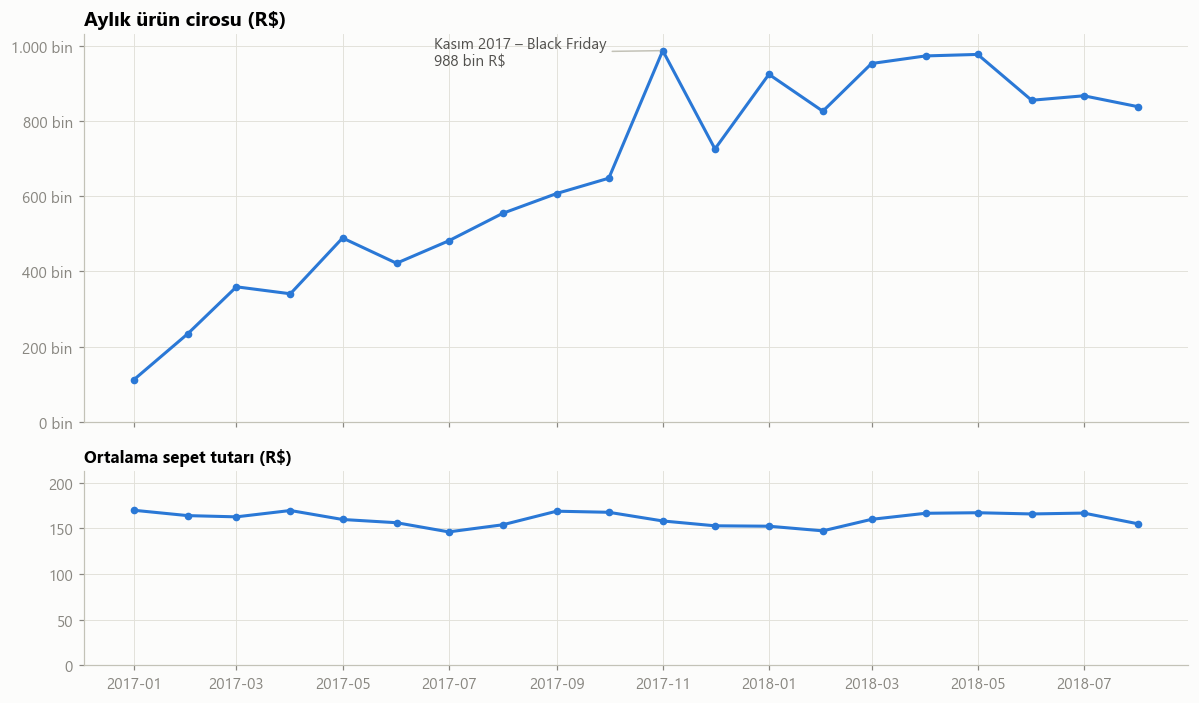

Ocak–Ağustos 2018 cirosu, 2017'nin aynı dönemine göre %141 daha yüksek.


In [8]:
aylik = df.groupby("ay").agg(ciro=("urun_tutari", "sum"), siparis=("order_id", "count"),
                             sepet=("siparis_tutari", "mean"))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[2, 1])
ax1.plot(aylik.index, aylik["ciro"], color=MAVI, marker="o", markersize=4)
ax1.set_title("Aylık ürün cirosu (R$)")
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{sayi(v / 1e3)} bin"))
ax1.set_ylim(0)
zirve = aylik["ciro"].idxmax()
ax1.annotate(f"Kasım 2017 – Black Friday\n{sayi(aylik.loc[zirve, 'ciro'] / 1e3)} bin R$",
             xy=(zirve, aylik.loc[zirve, "ciro"]), xytext=(-150, -10), textcoords="offset points",
             color=YAZI, arrowprops=dict(arrowstyle="-", color=ORTA_GRI))

ax2.plot(aylik.index, aylik["sepet"], color=MAVI, marker="o", markersize=4)
ax2.set_title("Ortalama sepet tutarı (R$)", fontsize=11)
ax2.set_ylim(0, aylik["sepet"].max() * 1.25)
fig.tight_layout()
kaydet(fig, "01_aylik_ciro")
plt.show()

buyume = aylik.loc["2018-01":"2018-08", "ciro"].sum() / aylik.loc["2017-01":"2017-08", "ciro"].sum() - 1
print(f"Ocak–Ağustos 2018 cirosu, 2017'nin aynı dönemine göre %{sayi(buyume * 100)} daha yüksek.")

Ciro 2017 boyunca hızla büyüyor, Kasım 2017'de (Black Friday) zirve yapıyor ve 2018'de aylık ~850–980 bin R$ bandında yatay seyrediyor.
Ortalama sepet tutarı ise neredeyse sabit: **büyüme, sepet büyüklüğünden değil sipariş sayısındaki artıştan geliyor.**

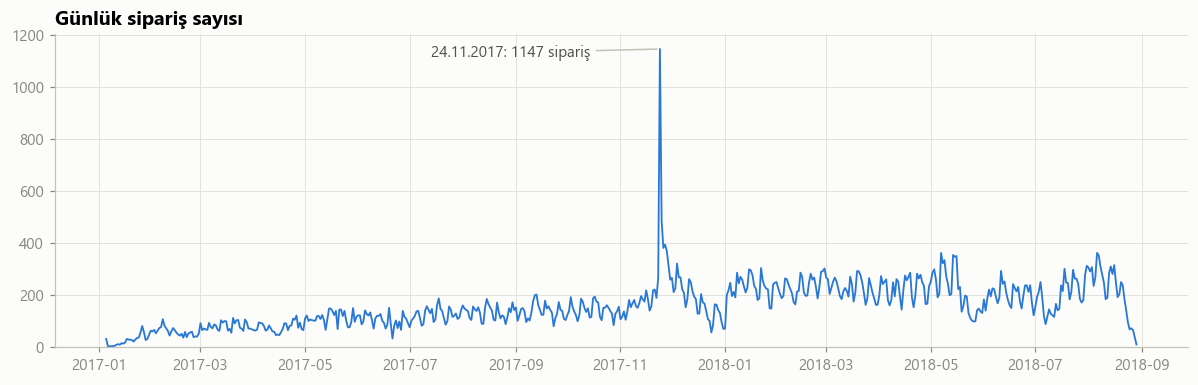

Günlük medyan: 148 sipariş — zirve günü medyanın 7.8 katı.


In [9]:
gunluk = df.set_index("order_purchase_timestamp").resample("D").size()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(gunluk.index, gunluk.values, color=MAVI, linewidth=1.2)
ax.set_title("Günlük sipariş sayısı")
ax.set_ylim(0)
zirve_gun = gunluk.idxmax()
ax.annotate(f"{zirve_gun:%d.%m.%Y}: {gunluk.max()} sipariş", xy=(zirve_gun, gunluk.max()),
            xytext=(-150, -5), textcoords="offset points", color=YAZI,
            arrowprops=dict(arrowstyle="-", color=ORTA_GRI))
fig.tight_layout()
kaydet(fig, "02_gunluk_siparis")
plt.show()
print(f"Günlük medyan: {gunluk.median():.0f} sipariş — zirve günü medyanın {gunluk.max() / gunluk.median():.1f} katı.")

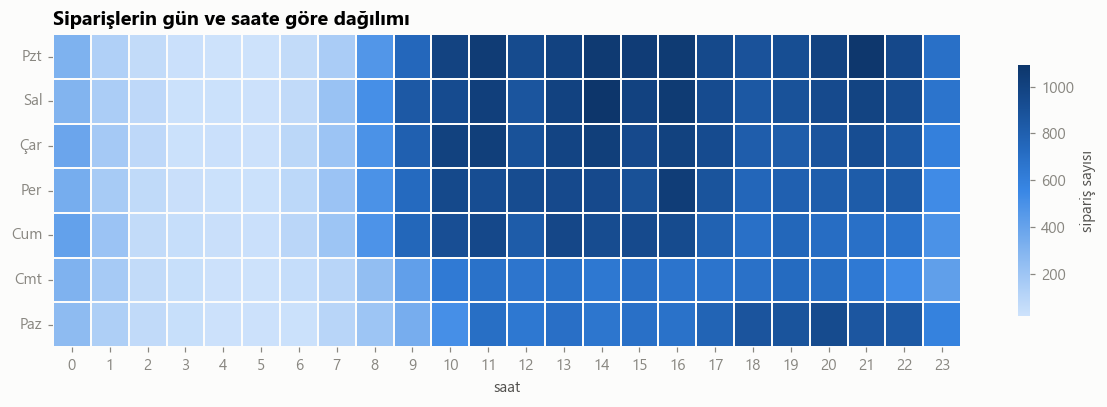

In [10]:
gunler = ["Pzt", "Sal", "Çar", "Per", "Cum", "Cmt", "Paz"]
isi = pd.crosstab(df["order_purchase_timestamp"].dt.dayofweek, df["order_purchase_timestamp"].dt.hour)
isi.index = gunler

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(isi, cmap=MAVI_RAMPA, linewidths=1, linecolor=YUZEY, ax=ax,
            cbar_kws={"label": "sipariş sayısı", "shrink": 0.8})
ax.set_title("Siparişlerin gün ve saate göre dağılımı")
ax.set_xlabel("saat")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
kaydet(fig, "03_gun_saat")
plt.show()

Siparişler **hafta içi 10:00–22:00** arasında yoğunlaşıyor; en sakin dönem gece 02:00–06:00 ve cumartesi günü.
Pazartesi ve salı en yoğun günler. Bu bilgi kampanya, e-posta ve müşteri hizmetleri planlamasında kullanılabilir.

## 5. Kategori analizi

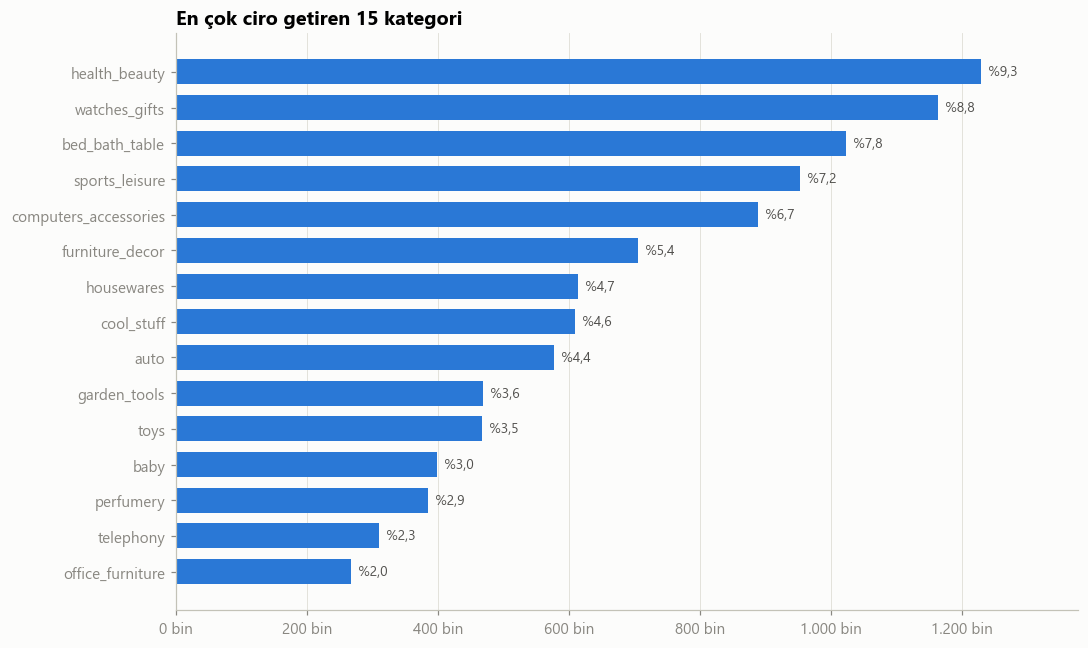

In [11]:
kategori = (kalem_df.groupby("kategori")
            .agg(ciro=("price", "sum"), adet=("order_item_id", "count"), ort_fiyat=("price", "mean"))
            .sort_values("ciro", ascending=False))
kategori["ciro_payi"] = kategori["ciro"] / kategori["ciro"].sum()

ilk15 = kategori.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(ilk15.index, ilk15["ciro"], color=MAVI, height=0.7)
for i, (c, p) in enumerate(zip(ilk15["ciro"], ilk15["ciro_payi"])):
    ax.text(c, i, f"  %{sayi(p * 100, 1)}", va="center", color=YAZI, fontsize=9)
ax.set_title("En çok ciro getiren 15 kategori")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{sayi(v / 1e3)} bin"))
ax.grid(axis="y", visible=False)
ax.set_xlim(0, ilk15["ciro"].max() * 1.12)
fig.tight_layout()
kaydet(fig, "04_kategoriler")
plt.show()

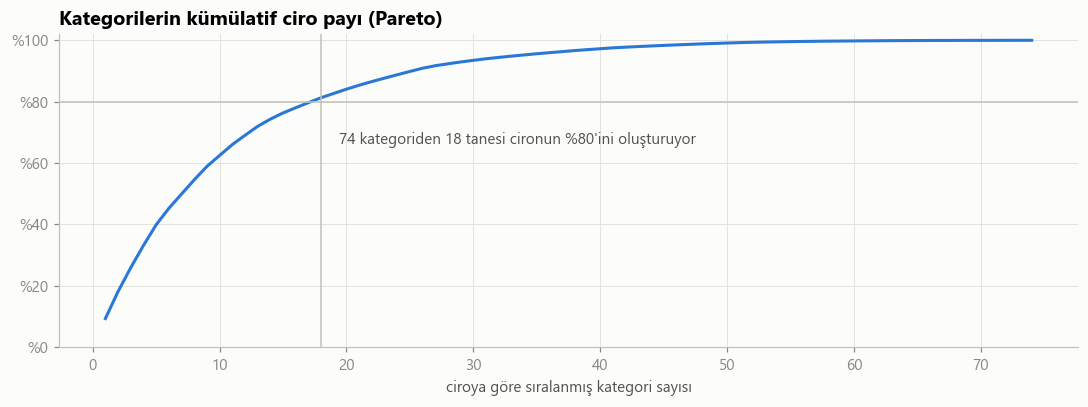

In [12]:
kumulatif = kategori["ciro_payi"].cumsum().reset_index(drop=True)
k80 = int((kumulatif < 0.8).sum()) + 1

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(np.arange(1, len(kumulatif) + 1), kumulatif * 100, color=MAVI)
ax.axhline(80, color=ORTA_GRI, linewidth=1)
ax.axvline(k80, color=ORTA_GRI, linewidth=1)
ax.annotate(f"{len(kategori)} kategoriden {k80} tanesi cironun %80'ini oluşturuyor", xy=(k80, 80),
            xytext=(12, -28), textcoords="offset points", color=YAZI)
ax.set_title("Kategorilerin kümülatif ciro payı (Pareto)")
ax.set_xlabel("ciroya göre sıralanmış kategori sayısı")
ax.yaxis.set_major_formatter(YUZDE)
ax.set_ylim(0, 102)
fig.tight_layout()
kaydet(fig, "05_pareto")
plt.show()

In [13]:
kategori.head(10).assign(
    ciro=lambda t: t["ciro"].map(sayi),
    ciro_payi=lambda t: (t["ciro_payi"] * 100).round(1),
).rename(columns={"ciro_payi": "ciro_payi (%)"})

,ciro,adet,ort_fiyat,ciro_payi (%)
kategori,,,,
health_beauty,1.229.558,9422,130.50,9.30
watches_gifts,1.163.188,5853,198.73,8.80
bed_bath_table,1.022.956,10945,93.46,7.80
sports_leisure,952.661,8413,113.24,7.20
computers_accessories,887.945,7631,116.36,6.70
furniture_decor,706.237,8095,87.24,5.40
housewares,614.342,6783,90.57,4.70
cool_stuff,609.158,3711,164.15,4.60
auto,577.721,4131,139.85,4.40


Ciro belirgin biçimde yoğunlaşmış: **sağlık-güzellik, saat-hediye ve ev tekstili** ilk üç sırada.
Saat-hediye kategorisi adet olarak daha az satsa da yüksek ortalama fiyatıyla ciroda ikinci sırada.

## 6. Bölgesel analiz

In [14]:
eyalet = (df.groupby("customer_state")
          .agg(siparis=("order_id", "count"), ciro=("urun_tutari", "sum"),
               medyan_teslim_gun=("teslim_suresi", "median"), gec_oran=("gec", "mean"),
               ort_puan=("review_score", "mean"), kargo=("kargo_ucreti", "sum"))
          .sort_values("siparis", ascending=False))
eyalet["siparis_payi"] = eyalet["siparis"] / eyalet["siparis"].sum()
eyalet["kargo_ciro_orani"] = eyalet["kargo"] / eyalet["ciro"]
eyalet.drop(columns="kargo").head(10)

,siparis,ciro,medyan_teslim_gun,gec_oran,ort_puan,siparis_payi,kargo_ciro_orani
customer_state,,,,,,,
SP,40399,"5,054,516.95",7.20,0.04,4.25,0.42,0.14
RJ,12310,"1,751,433.85",12.04,0.12,3.97,0.13,0.17
MG,11319,"1,548,206.88",10.31,0.05,4.19,0.12,0.17
RS,5327,"726,194.92",13.17,0.06,4.19,0.06,0.18
PR,4903,"664,048.00",10.42,0.04,4.24,0.05,0.17
SC,3537,"504,774.07",13.01,0.08,4.13,0.04,0.17
BA,3253,"493,339.26",16.91,0.12,3.93,0.03,0.20
DF,2074,"295,454.64",11.36,0.06,4.13,0.02,0.17
ES,1992,"267,783.66",13.63,0.11,4.08,0.02,0.18


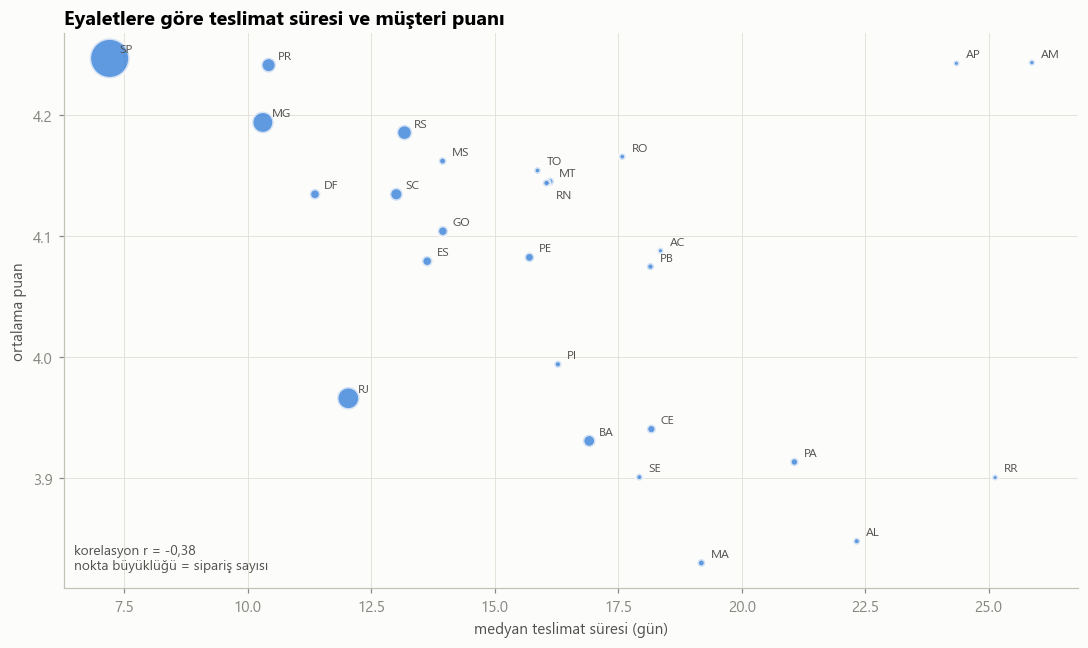

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(eyalet["medyan_teslim_gun"], eyalet["ort_puan"], s=eyalet["siparis"] / 60 + 15,
           color=MAVI, alpha=0.75, edgecolor=YUZEY, linewidth=2)
for kod, r in eyalet.iterrows():
    ax.annotate(kod, (r["medyan_teslim_gun"], r["ort_puan"]), xytext=(6, -10) if kod == "RN" else (6, 4),
                textcoords="offset points", fontsize=8, color=YAZI)
r = eyalet["medyan_teslim_gun"].corr(eyalet["ort_puan"])
ax.set_title("Eyaletlere göre teslimat süresi ve müşteri puanı")
ax.set_xlabel("medyan teslimat süresi (gün)")
ax.set_ylabel("ortalama puan")
ax.text(0.01, 0.03, f"korelasyon r = {sayi(r, 2)}\nnokta büyüklüğü = sipariş sayısı", transform=ax.transAxes,
        ha="left", va="bottom", color=YAZI, fontsize=9)
fig.tight_layout()
kaydet(fig, "06_eyaletler")
plt.show()

Siparişlerin ~%42'si tek başına **São Paulo (SP)** eyaletinden geliyor; SP, RJ ve MG birlikte siparişlerin ~2/3'ünü oluşturuyor.
Satıcıların da çoğu SP'de olduğu için, kuzey ve kuzeydoğu eyaletlerinde medyan teslimat süresi SP'ye göre 2–3,5 kat uzun (7 güne karşı 17–26 gün) ve kargo ücreti ürün tutarına oranla belirgin şekilde artıyor.
Eyaletler arasında **teslimat süresi uzadıkça ortalama puan genel olarak düşüyor** (r ≈ −0,38). Sağ üstteki AP (68) ve AM (148) çok az siparişe sahip; bu küçük örneklemler ilişkiyi zayıflatıyor.

## 7. Teslimat performansı ve müşteri memnuniyeti

In [16]:
puanli = df.dropna(subset=["review_score"])
gec_oran = df["gec"].mean()
dusuk = puanli.groupby("gec")["review_score"].apply(lambda s: (s <= 2).mean())
print(f"Geç teslim edilen sipariş oranı: %{sayi(gec_oran * 100, 1)}")
print(f"Medyan teslimat süresi: {df['teslim_suresi'].median():.1f} gün | "
      f"tahmini süreden ortalama {-df['gecikme_gun'].mean():.1f} gün önce teslim")
print(f"1–2 puan oranı: zamanında %{sayi(dusuk[False] * 100, 1)}, geç %{sayi(dusuk[True] * 100, 1)}")

Geç teslim edilen sipariş oranı: %6,8
Medyan teslimat süresi: 10.2 gün | tahmini süreden ortalama 11.8 gün önce teslim
1–2 puan oranı: zamanında %9,2, geç %62,4


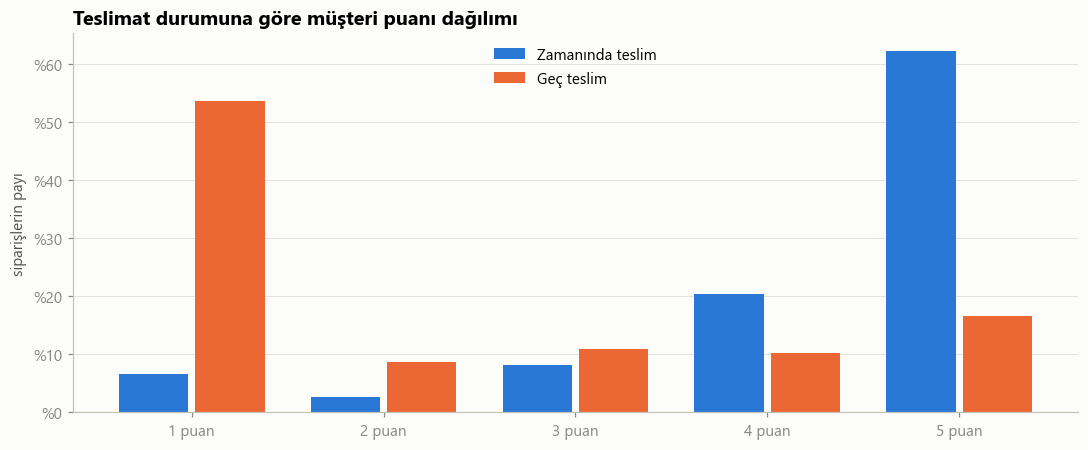

In [17]:
dagilim = (puanli.groupby("gec")["review_score"].value_counts(normalize=True)
           .unstack(0).reindex(range(1, 6)))

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(1, 6)
ax.bar(x - 0.2, dagilim[False] * 100, width=0.36, color=MAVI, label="Zamanında teslim")
ax.bar(x + 0.2, dagilim[True] * 100, width=0.36, color=TURUNCU, label="Geç teslim")
ax.set_xticks(x, [f"{p} puan" for p in x])
ax.yaxis.set_major_formatter(YUZDE)
ax.set_title("Teslimat durumuna göre müşteri puanı dağılımı")
ax.set_ylabel("siparişlerin payı")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center")
fig.tight_layout()
kaydet(fig, "07_puan_dagilimi")
plt.show()

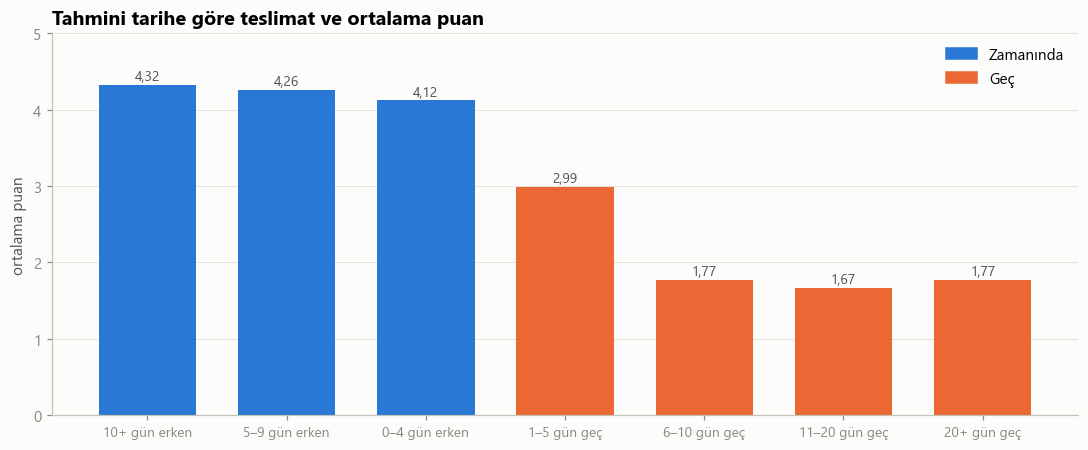

,ort_puan,siparis
gecikme_grubu,,
10+ gün erken,4.32,61270
5–9 gün erken,4.26,20027
0–4 gün erken,4.12,7885
1–5 gün geç,2.99,2721
6–10 gün geç,1.77,1634
11–20 gün geç,1.67,1260
20+ gün geç,1.77,763


In [18]:
sinirlar = [-np.inf, -10, -5, 0, 5, 10, 20, np.inf]
etiketler = ["10+ gün erken", "5–9 gün erken", "0–4 gün erken", "1–5 gün geç",
             "6–10 gün geç", "11–20 gün geç", "20+ gün geç"]
puanli = puanli.assign(gecikme_grubu=pd.cut(puanli["gecikme_gun"], sinirlar, labels=etiketler))
grup = puanli.groupby("gecikme_grubu", observed=True)["review_score"].agg(ort_puan="mean", siparis="count")

fig, ax = plt.subplots(figsize=(10, 4.2))
renkler = [MAVI] * 3 + [TURUNCU] * 4
ax.bar(grup.index.astype(str), grup["ort_puan"], color=renkler, width=0.7)
for i, (p, n) in enumerate(zip(grup["ort_puan"], grup["siparis"])):
    ax.text(i, p + 0.06, f"{sayi(p, 2)}", ha="center", color=YAZI, fontsize=9)
ax.set_ylim(0, 5)
ax.set_title("Tahmini tarihe göre teslimat ve ortalama puan")
ax.set_ylabel("ortalama puan")
ax.grid(axis="x", visible=False)
ax.tick_params(axis="x", labelsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=MAVI, label="Zamanında"), Patch(color=TURUNCU, label="Geç")],
          frameon=False, loc="upper right")
fig.tight_layout()
kaydet(fig, "08_gecikme_puan")
plt.show()
grup

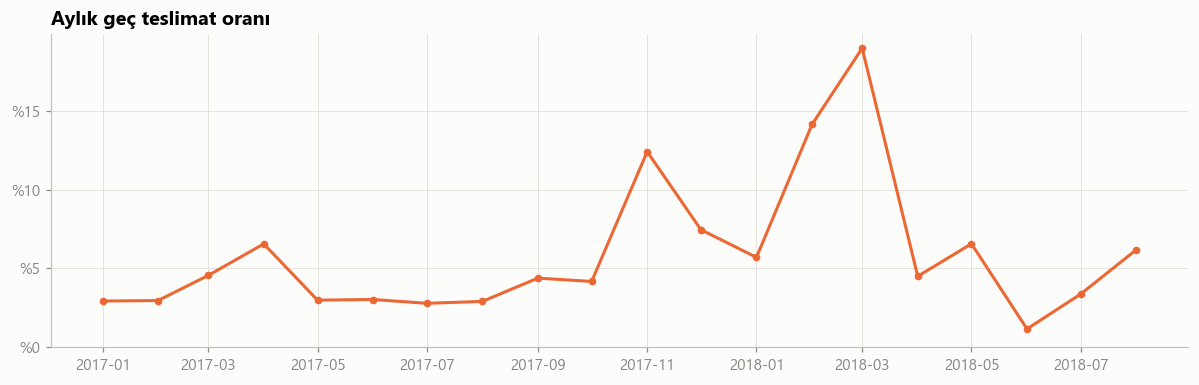

In [19]:
aylik_gec = df.groupby("ay")["gec"].mean() * 100

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(aylik_gec.index, aylik_gec.values, color=TURUNCU, marker="o", markersize=4)
ax.set_title("Aylık geç teslimat oranı")
ax.yaxis.set_major_locator(mtick.MultipleLocator(5))
ax.yaxis.set_major_formatter(YUZDE)
ax.set_ylim(0)
fig.tight_layout()
kaydet(fig, "09_aylik_gecikme")
plt.show()

**Projenin en güçlü bulgusu:** Teslimat tahmini tarihi aşıldığı anda puan keskin biçimde düşüyor.
Zamanında gelen siparişlerin ortalaması ~4,3 iken, birkaç gün geciken siparişlerde ~3'e, 5 günden fazla gecikenlerde ~1,7'ye iniyor.
Geç teslimat oranı Kasım 2017 (Black Friday) ve Şubat–Mart 2018'de sıçrıyor; yani **talep zirveleri lojistik kapasitesini zorluyor.**

## 8. Ödeme alışkanlıkları

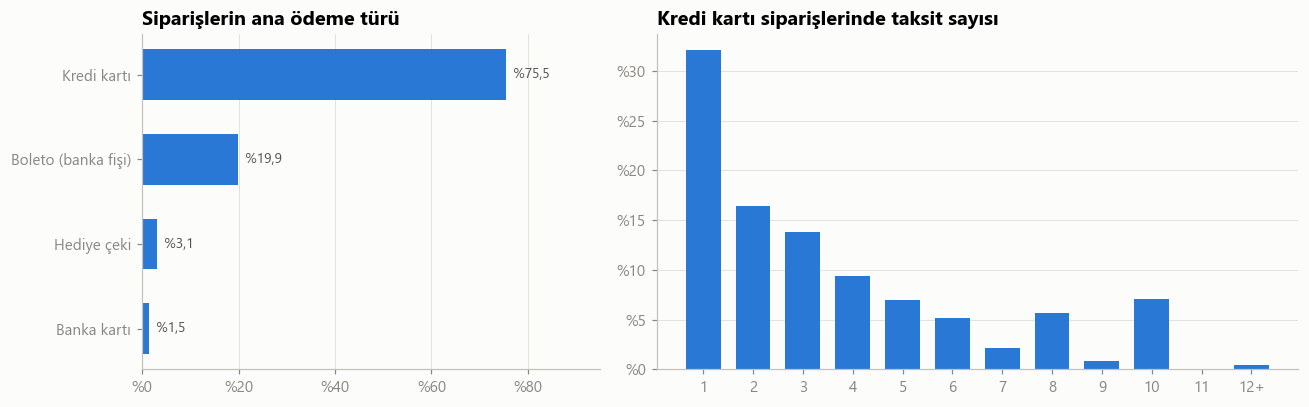

Taksitli kredi kartı siparişlerinin oranı: %68


In [20]:
od = odemeler[odemeler["order_id"].isin(df["order_id"]) & (odemeler["payment_type"] != "not_defined")]
ana_odeme = od.sort_values("payment_value").drop_duplicates("order_id", keep="last")
tur_adlari = {"credit_card": "Kredi kartı", "boleto": "Boleto (banka fişi)",
              "voucher": "Hediye çeki", "debit_card": "Banka kartı"}
tur = ana_odeme["payment_type"].map(tur_adlari).value_counts(normalize=True).iloc[::-1] * 100

kart = ana_odeme[ana_odeme["payment_type"] == "credit_card"]
taksit = kart["payment_installments"].clip(1, 12).value_counts(normalize=True).sort_index() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), width_ratios=[1, 1.4])
ax1.barh(tur.index, tur.values, color=MAVI, height=0.6)
for i, v in enumerate(tur.values):
    ax1.text(v, i, f"  %{sayi(v, 1)}", va="center", color=YAZI, fontsize=9)
ax1.set_title("Siparişlerin ana ödeme türü")
ax1.set_xlim(0, 95)
ax1.xaxis.set_major_formatter(YUZDE)
ax1.grid(axis="y", visible=False)

ax2.bar(taksit.index, taksit.values, color=MAVI, width=0.7)
ax2.set_title("Kredi kartı siparişlerinde taksit sayısı")
ax2.set_xticks(range(1, 13), [str(i) for i in range(1, 12)] + ["12+"])
ax2.yaxis.set_major_formatter(YUZDE)
ax2.grid(axis="x", visible=False)
fig.tight_layout()
kaydet(fig, "10_odeme")
plt.show()

print(f"Taksitli kredi kartı siparişlerinin oranı: %{sayi((kart['payment_installments'] > 1).mean() * 100)}")

In [21]:
taksit_grup = (df.merge(kart[["order_id", "payment_installments"]], on="order_id")
               .assign(taksit_grubu=lambda t: pd.cut(t["payment_installments"], [0, 1, 3, 6, 10, 24],
                                                      labels=["Tek çekim", "2–3", "4–6", "7–10", "10+"]))
               .groupby("taksit_grubu", observed=True)["siparis_tutari"].agg(["count", "median", "mean"]))
taksit_grup.columns = ["sipariş", "medyan tutar (R$)", "ortalama tutar (R$)"]
taksit_grup

,sipariş,medyan tutar (R$),ortalama tutar (R$)
taksit_grubu,,,
Tek çekim,23312,71.55,100.68
2–3,21960,111.61,135.02
4–6,15638,128.00,181.78
7–10,11371,205.83,333.08
10+,329,216.05,359.32


Brezilya'da kredi kartı baskın ödeme aracı ve **taksit kültürü güçlü**: kart ile ödenen siparişlerin yarısından fazlası taksitli.
Siparişlerin yaklaşık beşte biri, Brezilya'ya özgü banka fişi sistemi **boleto** ile ödeniyor.
Sipariş tutarı arttıkça taksit sayısı da artıyor; yüksek fiyatlı kategorilerde taksit kampanyaları satışları destekleyebilir.

## 9. Müşteri analizi ve RFM segmentasyonu

Veri setinde her sipariş için yeni bir `customer_id` üretildiğinden, gerçek müşteri kimliği olarak `customer_unique_id` kullanıldı.

In [22]:
musteri_siparis = df.groupby("customer_unique_id")["order_id"].count()
tekrar = (musteri_siparis > 1).mean()
print(f"Tekil müşteri: {sayi(len(musteri_siparis))}")
print(f"Birden fazla sipariş veren müşteri oranı: %{sayi(tekrar * 100, 1)}")
musteri_siparis.clip(upper=4).value_counts().sort_index().rename(index={4: "4+"}).to_frame("müşteri sayısı")

Tekil müşteri: 93.096
Birden fazla sipariş veren müşteri oranı: %3,0


,müşteri sayısı
order_id,
1,90307
2,2562
3,180
4+,47


Müşterilerin yalnızca ~%3'ü ikinci kez sipariş veriyor. Bu yüzden klasik RFM'deki *sıklık (F)* puanı beşe bölünemez.
Bunun yerine **güncellik (R)** ve **parasal değer (M)** beşe bölünerek 1–5 arası puanlandı, sıklık ise "tek sipariş / tekrar eden" olarak ikiye ayrıldı.

In [23]:
referans = df["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
rfm = df.groupby("customer_unique_id").agg(
    guncellik=("order_purchase_timestamp", lambda s: (referans - s.max()).days),
    siklik=("order_id", "count"),
    deger=("siparis_tutari", "sum"))
rfm["R"] = pd.qcut(rfm["guncellik"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M"] = pd.qcut(rfm["deger"], 5, labels=[1, 2, 3, 4, 5]).astype(int)


def segment(r):
    if r["siklik"] > 1:
        return "Şampiyonlar" if r["R"] >= 4 else "Sadık müşteriler"
    if r["R"] >= 4:
        return "Yeni – yüksek değerli" if r["M"] >= 4 else "Yeni müşteriler"
    if r["R"] <= 2:
        return "Kaybedilmek üzere – yüksek değerli" if r["M"] >= 4 else "Kaybedilmiş"
    return "Uykuda"


rfm["segment"] = rfm.apply(segment, axis=1)
seg = (rfm.groupby("segment")
       .agg(musteri=("R", "size"), ort_guncellik_gun=("guncellik", "mean"),
            ort_deger=("deger", "mean"), toplam_deger=("deger", "sum"))
       .sort_values("musteri", ascending=False))
seg["musteri_payi (%)"] = seg["musteri"] / seg["musteri"].sum() * 100
seg["deger_payi (%)"] = seg["toplam_deger"] / seg["toplam_deger"].sum() * 100
seg.drop(columns="toplam_deger")

,musteri,ort_guncellik_gun,ort_deger,musteri_payi (%),deger_payi (%)
segment,,,,,
Kaybedilmiş,22346,394.14,72.69,24.00,10.57
Yeni müşteriler,21764,89.97,72.89,23.38,10.32
Uykuda,18106,220.46,151.29,19.45,17.82
Yeni – yüksek değerli,14458,91.62,301.96,15.53,28.40
Kaybedilmek üzere – yüksek değerli,13633,391.88,307.74,14.64,27.29
Sadık müşteriler,1584,318.90,298.09,1.70,3.07
Şampiyonlar,1205,89.06,322.29,1.29,2.53


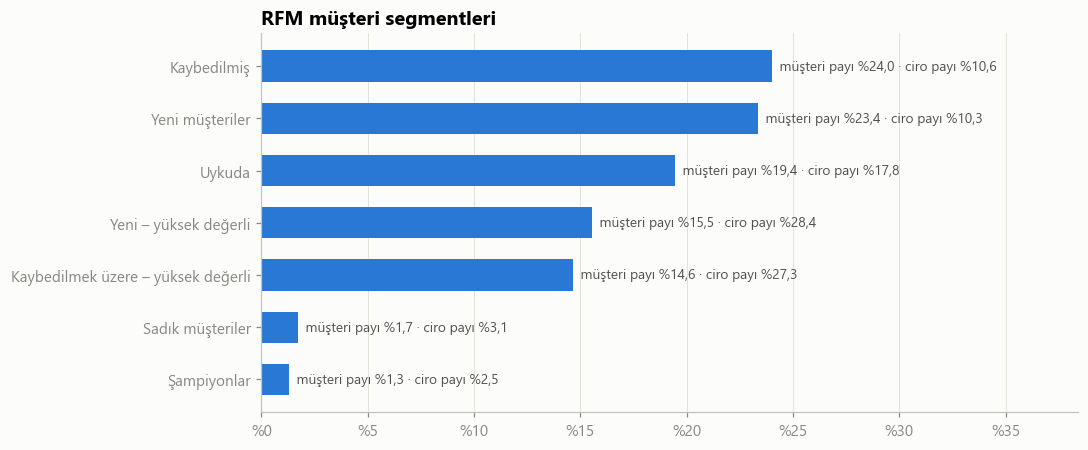

In [24]:
s = seg.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(s.index, s["musteri_payi (%)"], color=MAVI, height=0.6)
for i, (mp, dp) in enumerate(zip(s["musteri_payi (%)"], s["deger_payi (%)"])):
    ax.text(mp, i, f"  müşteri payı %{sayi(mp, 1)} · ciro payı %{sayi(dp, 1)}", va="center", color=YAZI, fontsize=9)
ax.set_title("RFM müşteri segmentleri")
ax.xaxis.set_major_formatter(YUZDE)
ax.set_xlim(0, s["musteri_payi (%)"].max() * 1.6)
ax.grid(axis="y", visible=False)
fig.tight_layout()
kaydet(fig, "11_rfm")
plt.show()

- **Şampiyonlar** (yakın zamanda birden fazla sipariş verenler) kişi başı en yüksek değere sahip ama müşterilerin yalnızca ~%1'i; sadakat programının çekirdeğini oluşturabilirler.
- **Kaybedilmek üzere – yüksek değerli** segment müşterilerin ~%15'i ama cironun ~%27'sini getirmiş. Geri kazanım (win-back) kampanyaları için en öncelikli hedef bu segment.
- **Yeni – yüksek değerli** müşteriler (cironun ~%28'i) ikinci siparişe yönlendirilirse, tekrar alım oranı en hızlı bu grupta artırılabilir.
- Tekrar alım oranının düşüklüğü, pazaryerinin müşteriyi elde tutmakta zorlandığını gösteriyor. Teslimat deneyimini iyileştirmek ilk kaldıraç olabilir (bkz. Bölüm 7).

## 10. Satıcı yoğunlaşması

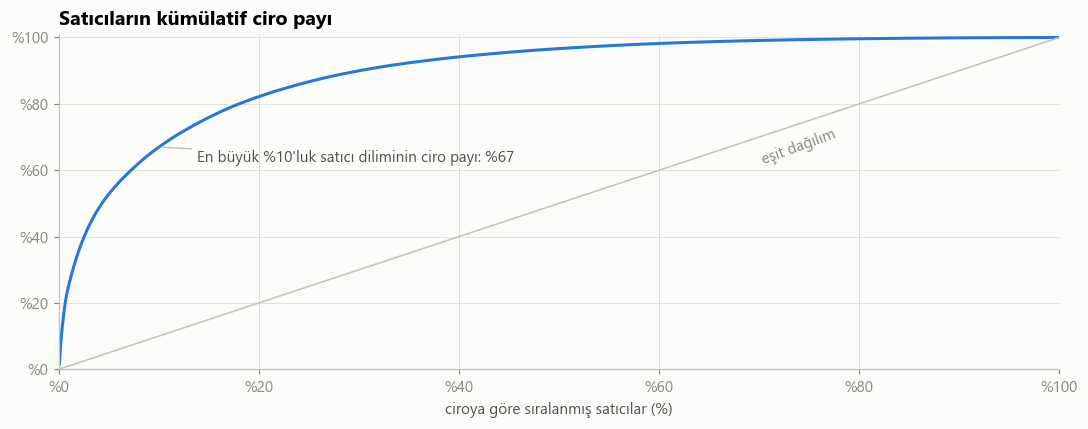

Satıcı sayısı: 2.945
Satıcıların eyalet dağılımı (%):
seller_state
SP   59.50
PR   11.30
MG    8.00
SC    6.20
RJ    5.50


In [25]:
satici_ciro = kalem_df.groupby("seller_id")["price"].sum().sort_values(ascending=False)
pay = satici_ciro.cumsum() / satici_ciro.sum() * 100
oran = np.arange(1, len(pay) + 1) / len(pay) * 100
ilk10 = pay.iloc[int(len(pay) * 0.1) - 1]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(oran, pay.values, color=MAVI)
ax.plot([0, 100], [0, 100], color=ORTA_GRI, linewidth=1)
ax.annotate(f"En büyük %10'luk satıcı diliminin ciro payı: %{sayi(ilk10)}", xy=(10, ilk10),
            xytext=(25, -10), textcoords="offset points", color=YAZI,
            arrowprops=dict(arrowstyle="-", color=ORTA_GRI))
ax.text(70, 62, "eşit dağılım", color="#898781", rotation=20)
ax.set_title("Satıcıların kümülatif ciro payı")
ax.set_xlabel("ciroya göre sıralanmış satıcılar (%)")
ax.xaxis.set_major_formatter(YUZDE)
ax.yaxis.set_major_formatter(YUZDE)
ax.set_xlim(0, 100)
ax.set_ylim(0, 101)
fig.tight_layout()
kaydet(fig, "12_saticilar")
plt.show()

print(f"Satıcı sayısı: {sayi(len(satici_ciro))}")
print("Satıcıların eyalet dağılımı (%):")
print((saticilar[saticilar["seller_id"].isin(satici_ciro.index)]["seller_state"]
       .value_counts(normalize=True).head(5) * 100).round(1).to_string())

Satıcı tarafında da güçlü bir yoğunlaşma var ve satıcıların büyük çoğunluğu SP eyaletinde.
Bu durum, uzak eyaletlerdeki uzun teslimat sürelerinin ve yüksek kargo maliyetlerinin temel nedeni.

## 11. Sonuçlar ve öneriler

### Temel bulgular
| # | Bulgu |
|---|---|
| 1 | Ocak 2017 – Ağustos 2018 arasında **96.203 teslim edilmiş siparişten 13,2 milyon R$** ürün cirosu elde edildi. 2018'in ilk 8 ayı, 2017'nin aynı dönemine göre **%141 büyüdü**. |
| 2 | Büyümenin kaynağı **sipariş sayısı**; ortalama sepet ~160 R$ civarında sabit kaldı. |
| 3 | Black Friday 2017'de günlük sipariş, medyan günün **~8 katına** çıktı. Siparişler hafta içi 10:00–22:00 arasında yoğunlaşıyor. |
| 4 | **74 kategoriden 18'i cironun %80'ini** oluşturuyor; ilk üç kategori sağlık-güzellik, saat-hediye ve ev tekstili. |
| 5 | Siparişlerin **%42'si SP** eyaletinden, satıcıların ise **%60'ı SP**'de. Uzak eyaletlerde medyan teslimat süresi 20 günü aşıyor. Eyalet bazında teslimat süresi ile ortalama puan arasında **orta düzeyde negatif bir ilişki (r = −0,38)** var. |
| 6 | Siparişlerin **%6,8'i geç** teslim edildi. Geç teslim edilen siparişlerde 1–2 puan oranı **%62**; zamanında teslim edilenlerde ise **%9**. Geç teslimat, düşük puanın en güçlü işareti. Ancak geç siparişlerin ~%75'inde değerlendirme anketi ürün ulaşmadan gönderilmiş; etkinin bir kısmı anket zamanlamasından kaynaklanıyor (bkz. 03 numaralı notebook). |
| 7 | Geç teslimat oranı talep zirvelerinde (Kasım 2017, Şubat–Mart 2018) **%12–19'a** sıçradı. |
| 8 | Ödemelerin **%75'i kredi kartı**, %20'si boleto. Kartla ödenen siparişlerin **%68'i taksitli** ve taksit sayısı sepet tutarıyla birlikte artıyor. |
| 9 | Müşterilerin yalnızca **%3'ü** ikinci kez sipariş verdi. Elde tutma, platformun en zayıf halkası. |
| 10 | Satıcıların **ilk %10'u cironun ~%67'sini** getiriyor. |

### Öneriler
1. **Teslimat sözünü koru:** Kampanya dönemlerinden önce lojistik kapasitesini artır ve tahmini teslim tarihlerini talep yoğunluğuna göre dinamik hesapla. Gecikmesi öngörülen siparişlerde müşteriyi önceden bilgilendir ve telafi kuponu sun.
2. **Bölgesel genişleme:** Kuzey ve kuzeydoğu eyaletlerinden satıcı kazan veya bölgesel depo kur. Bu, hem teslimat süresini hem de ürün tutarına oranla yüksek kalan kargo ücretini düşürür.
3. **Elde tutma programı:** İlk siparişten 30–60 gün sonra kişiselleştirilmiş teklif gönder. Bütçeyi önce *yeni – yüksek değerli* ve *kaybedilmek üzere – yüksek değerli* segmentlere ayır.
4. **Taksit kampanyaları:** Saat-hediye, bilgisayar gibi yüksek fiyatlı kategorilerde faizsiz taksit seçeneklerini öne çıkar.
5. **Zamanlama:** E-posta ve bildirim kampanyalarını hafta içi öğle saatlerine ve pazar akşamına planla.

### Sınırlılıklar
- Analiz teslim edilmiş siparişlerle sınırlı; iptal edilen siparişlerin nedenleri incelenmedi.
- Gecikme ile puan arasındaki ilişki **korelasyondur**; ürün kalitesi gibi başka etkenler de puanı etkiliyor olabilir.
- Veri Ağustos 2018'de kesiliyor; mevsimsellik yalnızca bir Black Friday üzerinden gözlemlenebiliyor.

### Devamı
- **02 · Coğrafi analiz:** müşteri ve satıcı haritaları, mesafenin teslimata etkisi.
- **03 · Duygu analizi:** Portekizce yorumlarla duygu modeli ve şikâyet konuları.
- **04 · Geç teslimat modeli:** sipariş anında gecikme riskini tahmin eden model.
- **Dashboard:** `dashboard/olist_panosu.html` dosyasında filtrelenebilir etkileşimli pano.